In [32]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [33]:
df = pd.read_csv("../datasets/train.csv")
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [34]:
df.columns

Index(['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g',
       'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height',
       'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi', 'price_range'],
      dtype='str')

In [35]:
df["PixelArea"] = (df["px_height"] * df["px_width"]) / 1000
df["ScreenArea"] = df["sc_h"] * df["sc_w"]

df = df.drop(["px_height", "px_width", "sc_h", "sc_w"], axis = 1)
df.shape

(2000, 19)

In [36]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,ram,talk_time,three_g,touch_screen,wifi,price_range,PixelArea,ScreenArea
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,9.916500,2124.213000,11.011000,0.761500,0.503000,0.507000,1.500000,905.260053,80.257000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,6.064315,1084.732044,5.463955,0.426273,0.500116,0.500076,1.118314,829.762497,76.824156
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,0.000000,256.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,5.000000,1207.500000,6.000000,1.000000,0.000000,0.000000,0.750000,263.200500,19.000000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,10.000000,2146.500000,11.000000,1.000000,1.000000,1.000000,1.500000,601.359000,55.000000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,15.000000,3064.500000,16.000000,1.000000,1.000000,1.000000,2.250000,1359.027250,121.500000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,20.000000,3998.000000,20.000000,1.000000,1.000000,1.000000,3.000000,3886.306000,342.000000


In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  ram            2000 non-null   int64  
 12  talk_time      2000 non-null   int64  
 13  three_g        2000 non-null   int64  
 14  touch_screen   2000 non-null   int64  
 15  wifi           2000 non-null   int64  
 16  price_range    2000 non-null   int64  
 17  PixelArea      2000 non-null   float64
 18  ScreenArea     2000

In [38]:
df.isnull().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
ram              0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
PixelArea        0
ScreenArea       0
dtype: int64

In [39]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='price_range', ylabel='count'>

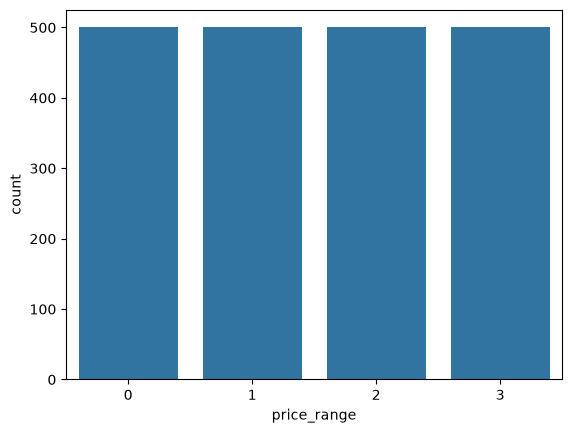

In [40]:
sns.countplot(x = "price_range", data = df) # all the data is equally split - so this is a very well balanced dataset 

<Axes: xlabel='battery_power', ylabel='Density'>

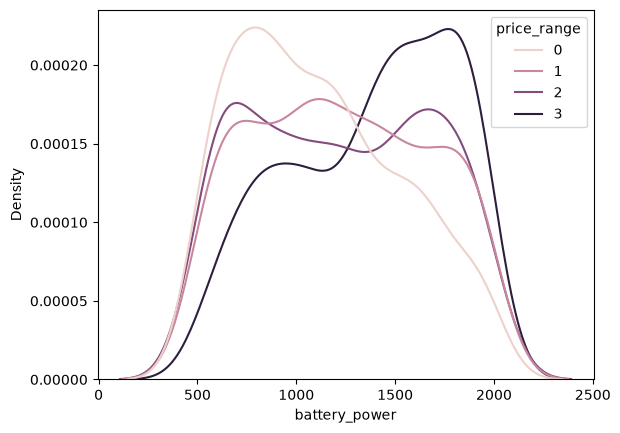

In [41]:
sns.kdeplot(x = "battery_power", data = df, hue = "price_range") # can be converted to normal using power transformer if required \
# price range 1, 2 are mostly centered whereas the price range 0 and the price range 3 are left and right skewed
# this for price range 1 and 2 we have good options of phones with low and high battery 
# but for price range 3 most of the phones have a better battery 
# price range 0 have mostly poor battery power 

blue
0    1010
1     990
Name: count, dtype: int64

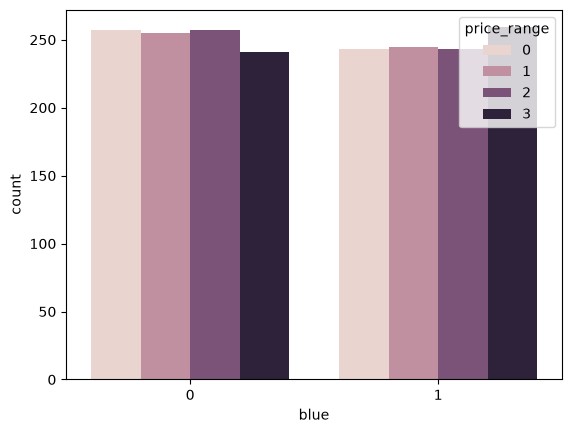

In [42]:
sns.countplot(x = "blue", data = df, hue = "price_range")
df["blue"].value_counts() # almost equal split of phones having no bluetooth and bluetooth
# it is also equally split between the price ranges

<Axes: xlabel='clock_speed', ylabel='Density'>

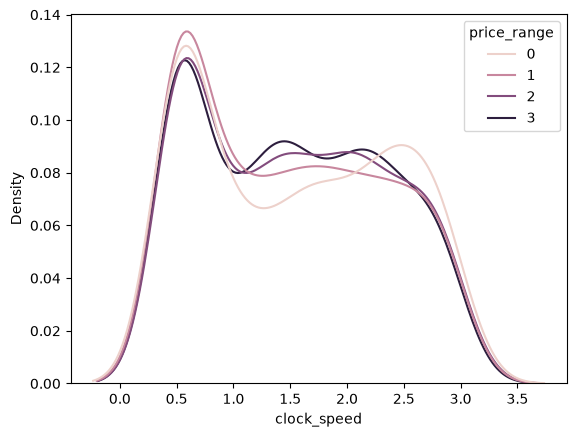

In [43]:
sns.kdeplot(x = "clock_speed", data = df, hue = "price_range")

# the processor used in all the four price range phones are almost similar in nature 

<Axes: xlabel='dual_sim', ylabel='count'>

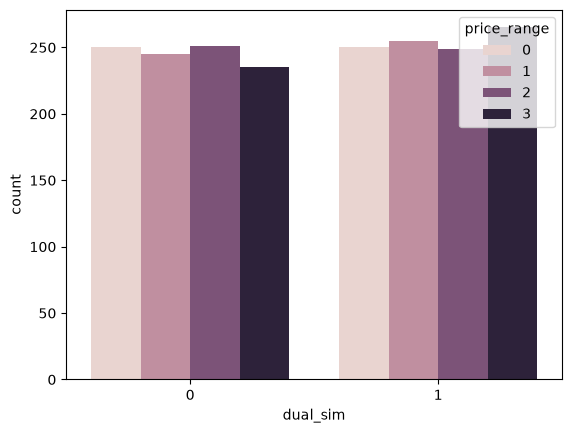

In [44]:
sns.countplot(x = "dual_sim", data = df, hue = "price_range") # again an uniform  distribution of single and dual sim phones across the price ranges 

<Axes: xlabel='fc', ylabel='Density'>

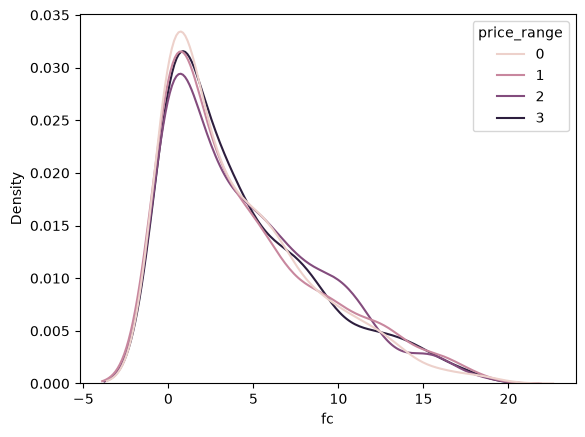

In [45]:
sns.kdeplot(x = "fc", data = df, hue = "price_range") # similar front camera pixel distribution for the phones in different price ranges
# however, as the price increases, we can find more phones with a better processor 

<Axes: xlabel='four_g', ylabel='count'>

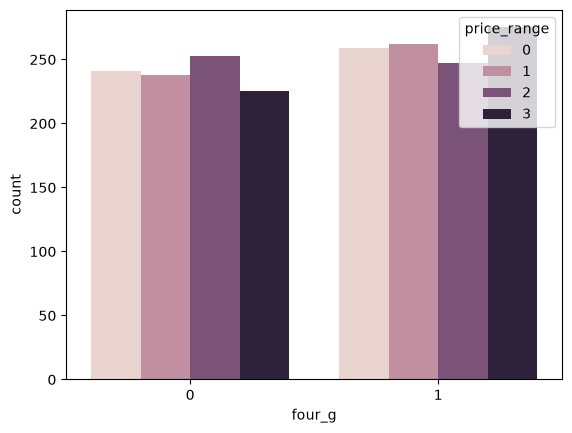

In [46]:
sns.countplot(x = "four_g", data = df, hue = "price_range") # there are more phones with 4g than phones without 4g 
# out of the phones without 4g there is an almost equal distribution with price range 3 having lesser number of non 4g phones 
# out of the phones with 4g there is more number of phones in the price range 3 but still the distribution is close to a uniform distribution

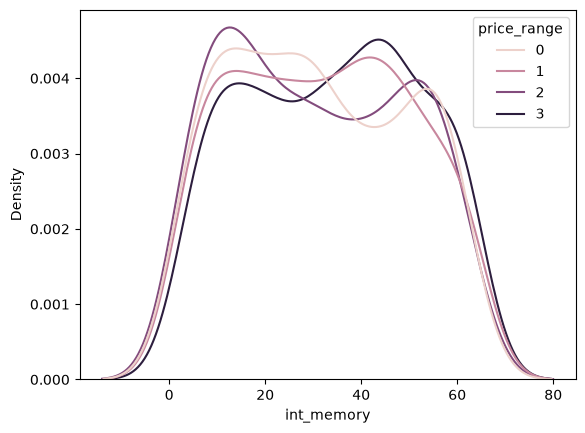

In [47]:
sns.kdeplot(x = "int_memory", data = df, hue = "price_range")
plt.show() # as price range increases, the internal memory tends to increase 
# price range 1 has more value for money when it comes to internal memory 

<Axes: xlabel='m_dep', ylabel='Density'>

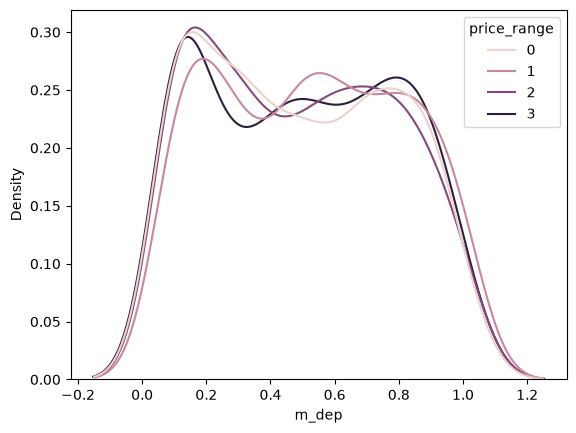

In [48]:
sns.kdeplot(x = "m_dep", data = df, hue = "price_range") # almost the same distribution for depth of the phone for different price ranges 

<Axes: xlabel='mobile_wt', ylabel='Density'>

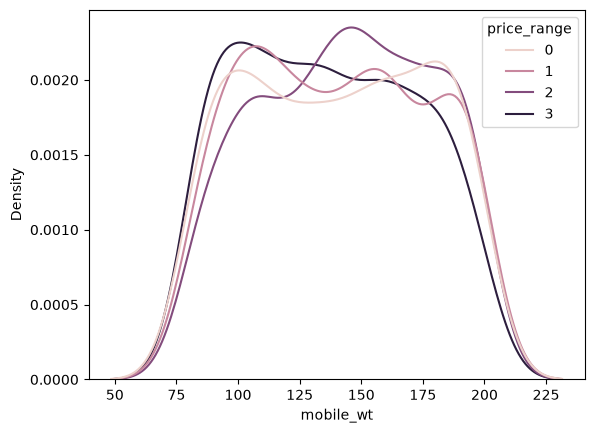

In [49]:
sns.kdeplot(x = "mobile_wt", data = df, hue = "price_range") # as price increases, mobile weight is found to decrease

<Axes: xlabel='n_cores', ylabel='count'>

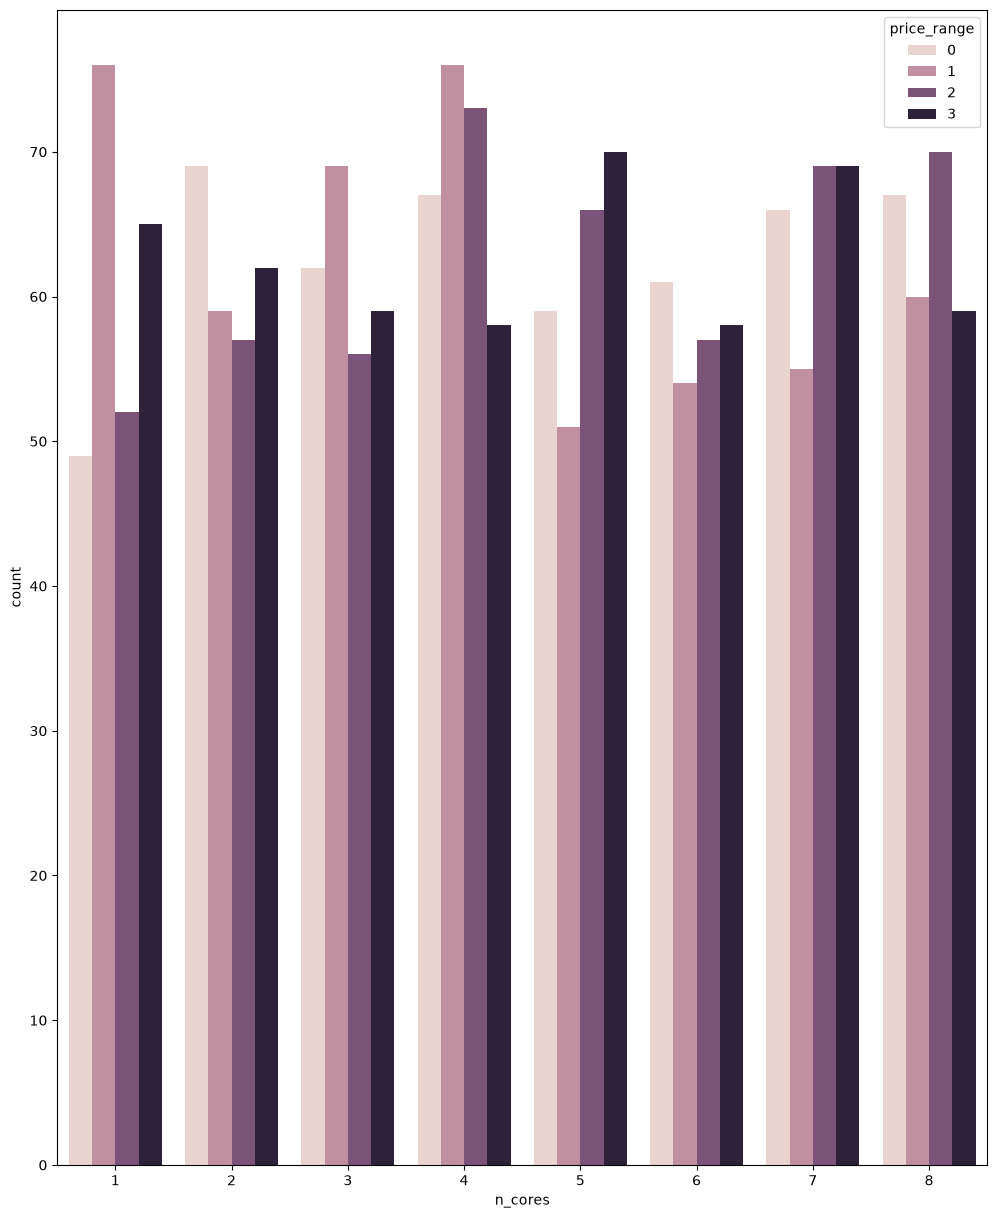

In [50]:
plt.figure(figsize = (12, 15))
sns.countplot(x = "n_cores", data = df, hue = "price_range") 

# phone of price range 1 tends to use lesser processor core and phone of price range 2 gives better value for money if the requirement is performance 

<Axes: xlabel='pc', ylabel='Density'>

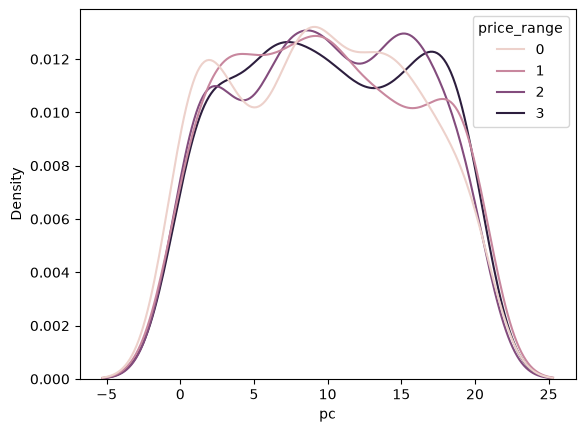

In [51]:
sns.kdeplot(x = "pc", hue = "price_range", data = df) # some noise is present in this data 
# as the price range increases there is more phones with a better camera quality than the cheaper ones 
# phones of price range 3 gives better value for money if the requirement is camera

<Axes: xlabel='PixelArea', ylabel='Density'>

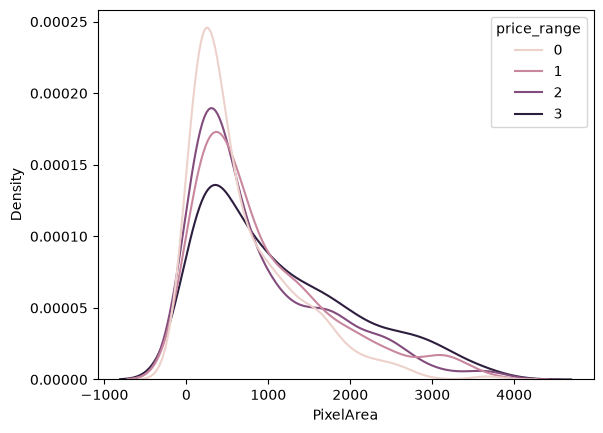

In [52]:
sns.kdeplot(x = "PixelArea", hue = "price_range", data = df) 
# more the price - more the screen area - that is bigger phone 
# if the requirement is to have a bigger screen then go with phone 3 

<Axes: xlabel='ram', ylabel='Density'>

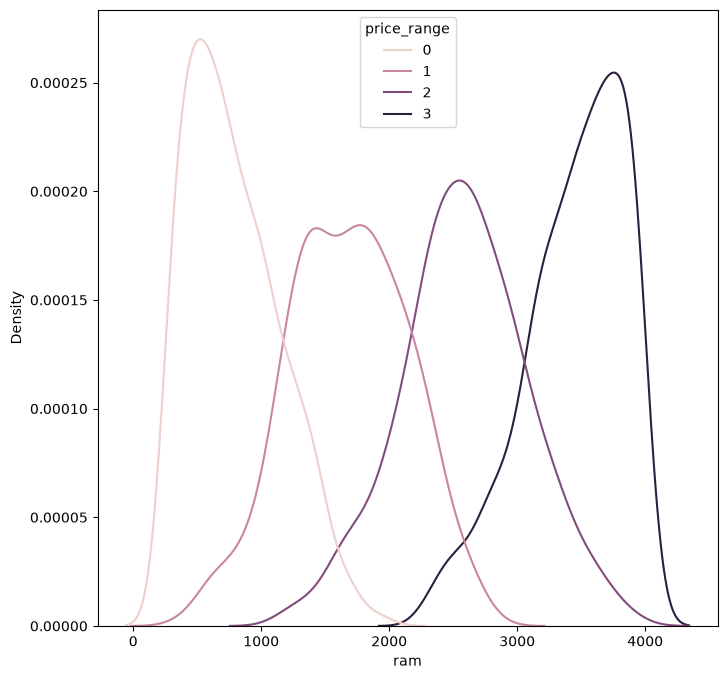

In [53]:
plt.figure(figsize = (8,8))
sns.kdeplot(x = "ram", hue = "price_range", data = df) 

# as price increases, the ram increases and this is the place which makes more difference in terms of price vs quality 
# if the ram is the requirement go with price 3

<Axes: xlabel='talk_time', ylabel='Density'>

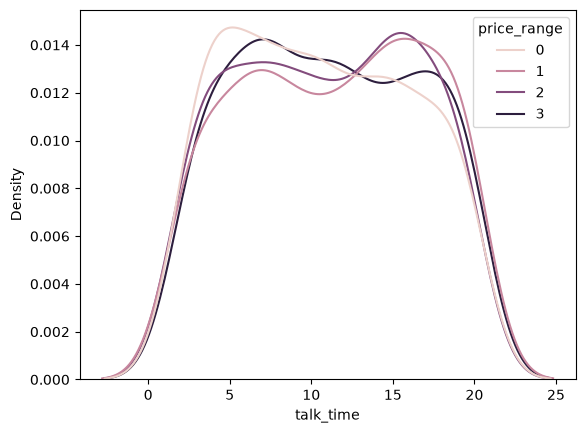

In [54]:
sns.kdeplot(x = "talk_time", hue = "price_range", data = df) # price range 2 has the better battery overall. so if the battery is the requirement - go with price_range 2 

<Axes: xlabel='three_g', ylabel='count'>

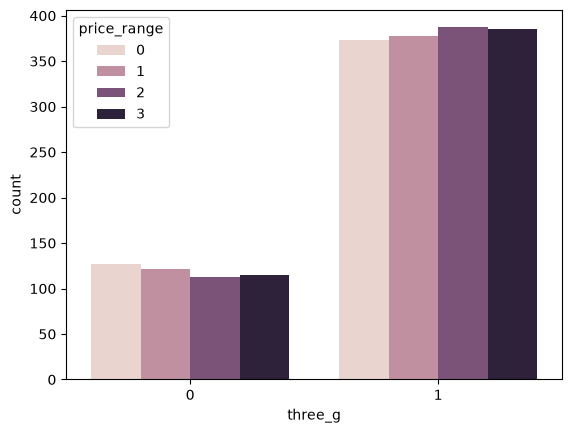

In [55]:
sns.countplot(x = "three_g", hue = "price_range", data = df) # most of the phones support 3g or more 
# there is a uniform distribution of phones for price_range/ having 3g support or not 

<Axes: xlabel='touch_screen', ylabel='count'>

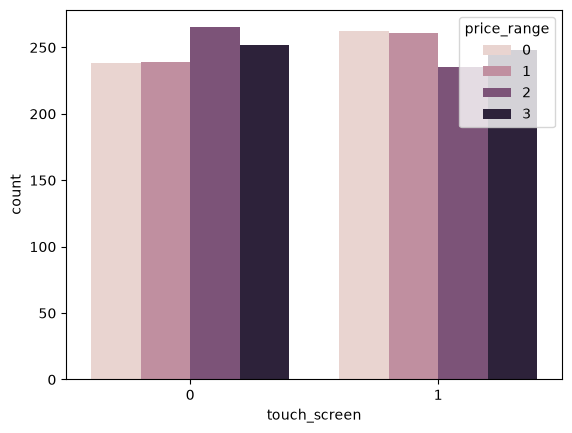

In [56]:
sns.countplot(x = "touch_screen", hue = "price_range", data = df) # price range 0 and 1 have touch screen phones generally 

<Axes: xlabel='wifi', ylabel='count'>

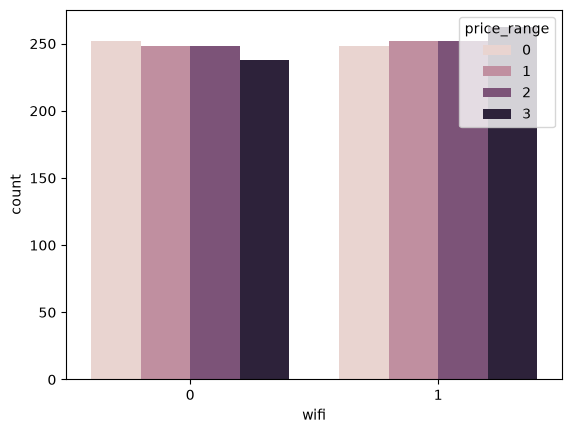

In [57]:
sns.countplot(x = "wifi", hue = "price_range", data = df) # higher price phones have wifi support )generally than low price range phones 

In [58]:
df.to_csv("../datasets/processed_dataset_train.csv", index = False)

In [59]:
df = pd.read_csv("../datasets/test.csv")

In [60]:
df["PixelArea"] = (df["px_height"] * df["px_width"]) / 1000
df["ScreenArea"] = df["sc_h"] * df["sc_w"]

df = df.drop(["px_height", "px_width", "sc_h", "sc_w"], axis = 1)

In [61]:
df.to_csv("../datasets/processed_dataset_test.csv", index = False)